In [1]:
import pandas as pd

df = pd.read_csv("data.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print("Missing values:\n", df.isnull().sum().sum())


Dataset shape: (569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_wors

In [2]:
df = df.drop(columns=["id", "Unnamed: 32"])

In [3]:
# Check target distribution
print(df["diagnosis"].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


In [4]:
print("Missing values:", df.isnull().sum().sum())

Missing values: 0


In [5]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (569, 30)
Target shape: (569,)


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9649122807017544


In [8]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test,
    y_pred,
    target_names=["Benign", "Malignant"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Confusion Matrix:
[[71  1]
 [ 3 39]]


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.9736842105263158


In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="recall",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV recall:", grid.best_score_)

Best parameters: {'max_depth': None, 'n_estimators': 50}
Best CV recall: 0.9529411764705882


In [11]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

print(importance.sort_values(ascending=False).head(10))

area_worst              0.151412
concave points_worst    0.126497
radius_worst            0.093475
perimeter_worst         0.083642
concave points_mean     0.081082
perimeter_mean          0.077126
radius_mean             0.061990
concavity_mean          0.050818
area_mean               0.045916
concavity_worst         0.030022
dtype: float64


In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

In [13]:
from sklearn.metrics import recall_score

print("Original recall:", recall_score(y_test, y_pred))

balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    ))
])

balanced_model.fit(X_train, y_train)
balanced_pred = balanced_model.predict(X_test)

print("Balanced recall:", recall_score(y_test, balanced_pred))

Original recall: 0.9285714285714286
Balanced recall: 0.9523809523809523


In [14]:
from sklearn.metrics import roc_auc_score

y_prob = balanced_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9953703703703703


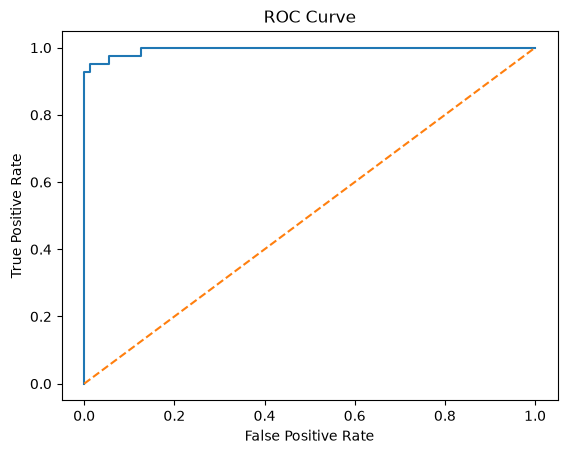

In [16]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

In [17]:
import numpy as np
from sklearn.metrics import recall_score, precision_score

# Malignant probabilities
y_prob = balanced_model.predict_proba(X_test)[:, 1]

# Set threshold
threshold = 0.3

# Convert probabilities into predictions
y_pred_03 = (y_prob >= threshold).astype(int)

print("Recall:", recall_score(y_test, y_pred_03))
print("Precision:", precision_score(y_test, y_pred_03))

Recall: 0.9523809523809523
Precision: 0.9523809523809523


In [18]:
y_pred_05 = (y_prob >= 0.5).astype(int)

print("Recall:", recall_score(y_test, y_pred_05))
print("Precision:", precision_score(y_test, y_pred_05))

Recall: 0.9523809523809523
Precision: 0.975609756097561


In [19]:
y_pred_07 = (y_prob >= 0.7).astype(int)

print("Recall:", recall_score(y_test, y_pred_07))
print("Precision:", precision_score(y_test, y_pred_07))

Recall: 0.9047619047619048
Precision: 1.0


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred,
    "Random Forest": rf_pred
}

for name, predictions in models.items():
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1-score:", f1_score(y_test, predictions))


Logistic Regression
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1-score: 0.9512195121951219

Random Forest
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1-score: 0.9629629629629629


In [25]:
import joblib

loaded_model = joblib.load("breast_cancer_model.pkl")

print("Model loaded successfully!")

prediction = loaded_model.predict(X_test)

print("First 5 predictions:", prediction[:5])

Model loaded successfully!
First 5 predictions: [0 1 0 1 0]
